# Reliability diagrams on the test set (final model)

Final model: single split (no folds), CT + box mask input, class-weighted cross-entropy loss (`train_no_fold.py --mask --loss weighted`), runs in `runs/cls_no_fold_mask_weighted`.

Calibration of models A and B on the 290 test nodules: for each confidence level, how often the predicted rating
matched the median rating. For each model, the test predictions of seeds 1-3 are **pooled**
(3 × 290 = 870 predictions), so the bins hold more predictions than one run would.

Drawn with `_reliability_png` from `plots.py`, the same function as the validation diagrams.
**Reading them:** bars above the dashed line = underconfident (right more often than it claims),
below = overconfident. The number on each bar is how many predictions are in that bin; pale bars have fewer than 10.

The ECE in each title is the ECE of the 870 pooled predictions, so it is not the same as the mean ECE over seeds
in `summary.csv` (that one is checked below).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
from IPython.display import Image, display

PROJECT = Path.cwd().parent if Path.cwd().name == "Model" else Path.cwd()
sys.path.insert(0, str(PROJECT / "Model"))       # plots.py
sys.path.insert(0, str(PROJECT / "pipeline"))    # metrics.py
import metrics as M
from plots import _reliability_png

RUNS_DIR = PROJECT / "runs" / "cls_no_fold_mask_weighted"
OUT_DIR = PROJECT / "results" / "test_no_fold_mask_weighted"     # saved next to the other test results of this model
SEEDS = [1, 2, 3]
RATINGS = [1, 2, 3, 4, 5]
P_COLS = [f"p{k}" for k in RATINGS]
KINDS = {"hard": "A", "soft": "B"}

# check these are the final model's runs: CT + mask input, class-weighted loss
for kind in KINDS:
    for s in SEEDS:
        cfg = json.loads((RUNS_DIR / f"{kind}_seed{s}" / "config.json").read_text())
        assert cfg.get("mask") and cfg.get("loss") == "weighted", f"{kind}_seed{s} is not a mask + weighted run"

labels = pd.read_csv(PROJECT / "data" / "nodules_labels.csv")
test = labels[labels["split"] == "test"].set_index("nodule_key")
hard = test["hard"].to_numpy()
print(f"{len(test)} test nodules")

def probs_of(run):
    """One run's test probabilities, rows in the order of the test nodules."""
    preds = pd.read_csv(RUNS_DIR / run / "test_preds.csv").set_index("nodule_key")
    return preds.loc[test.index, P_COLS].to_numpy()

290 test nodules


## Check: each seed's ECE averages to the value in summary.csv from the scoring script

In [2]:
summary = pd.read_csv(OUT_DIR / "summary.csv", header=[0, 1], index_col=0)
for kind, m in KINDS.items():
    mean_ece = np.mean([M.ece(probs_of(f"{kind}_seed{s}"), hard) for s in SEEDS])
    print(f"model {m}: mean ECE over seeds here {mean_ece:.3f}, in summary.csv {summary.filter(like=m, axis=0)[('ece', 'mean')].iloc[0]:.3f}")

model A: mean ECE over seeds here 0.053, in summary.csv 0.053
model B: mean ECE over seeds here 0.092, in summary.csv 0.092


## Pool each model's 3 seeds, then draw and show the diagrams

results/test_no_fold_mask_weighted/reliability_hard_pooled.png


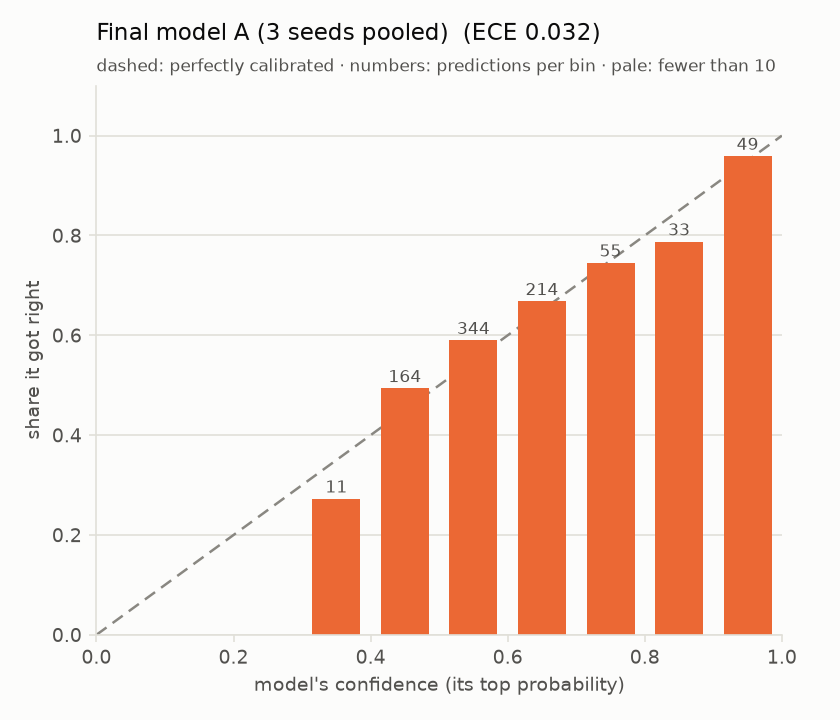

results/test_no_fold_mask_weighted/reliability_soft_pooled.png


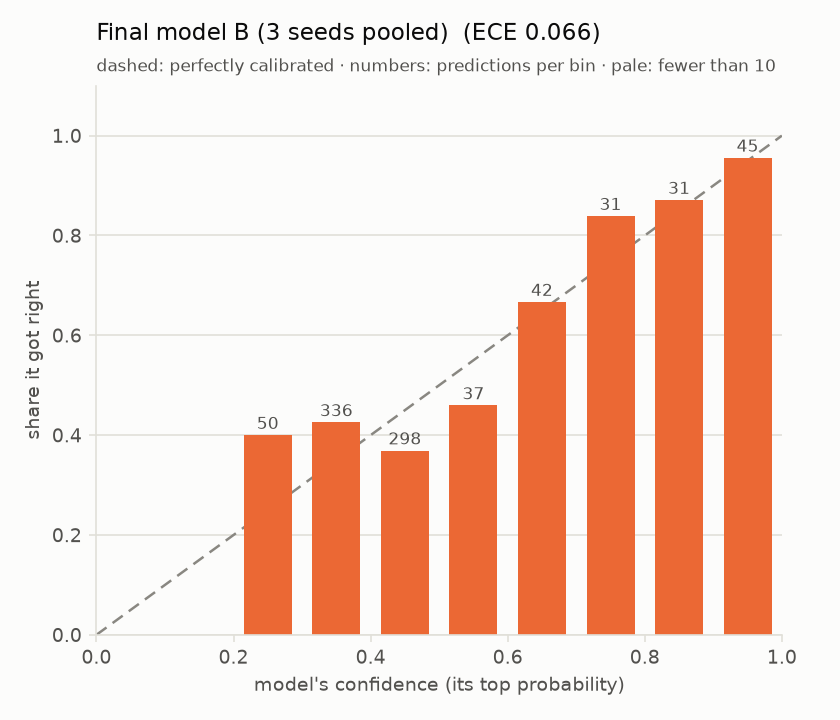

In [3]:
matplotlib.use("Agg")      # _reliability_png saves to a file; the saved file is shown below
for kind, m in KINDS.items():
    pooled = np.concatenate([probs_of(f"{kind}_seed{s}") for s in SEEDS])
    h = np.tile(hard, len(SEEDS))          # each test nodule appears once per seed
    path = OUT_DIR / f"reliability_{kind}_pooled.png"
    _reliability_png(pooled, h, M.ece(pooled, h), f"Final model {m} (3 seeds pooled)", path, counted="predictions")
    print(path.relative_to(PROJECT))
    display(Image(filename=str(path), width=480))